# How much better is the best model?, single units only → `figure_model_comparison_good.pdf`

[`../figure_4/figure_model_comparison.ipynb`](../figure_4/figure_model_comparison.ipynb)'s
panel, drawn over well-isolated single units only, so a reader can see that the result is not carried by
multi-unit clusters, whose spikes may come from several neurons with different tuning.

**What the point and its whisker are.** The point is the *population* estimate — the total
held-out log-likelihood difference over all neurons and trials, divided by the total trial
count — and the whisker is a **95% confidence interval of the mean across neurons**, with each
neuron treated as one independent observation regardless of session. What it does not cover is
session-to-session variation: simultaneously recorded neurons share trials, share a stimulus
sequence and have correlated receptive fields, so the session is the unit that is plausibly
independent, and the cluster-robust error across sessions is wider by `inflation`. Both are
computed here and printed beside each other, so the size of that gap is visible rather than
asserted. The axis is a likelihood rather than a log-likelihood: the reference sits at 1, and
0.91 means each held-out trial is 9% less likely under that model.

*This notebook replaced a softmax-posterior panel on 2026-09-13*, when the main figure did.
That panel softmaxed the summed held-out log-likelihood of a resampled dataset of 30 neurons
contributing one trial each: its error bar was Monte-Carlo precision, so it shrank as the
replicate count rose, and its violin width was set by that arbitrary 30 × 1 dataset size. Two
analyst choices set what a reader saw and neither was a property of the data. This scale has no
such free parameter in it — which matters more here than in the main figure, since a
supplement's whole job is to be comparable with it.

Nothing is refit: every number comes from the cached `dtest_ll_mean` (the paired per-split
held-out ΔLL against a constant fit to the same trials) times each neuron's trial count.
The group filter comes first, so the reference model and every difference are judged within
the population actually drawn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
common.set_style()
import elpd_lib as el
import models_lib as ml

# ── These must match ../figure_4/figure_model_comparison.ipynb ────────────────
# The supplement is that panel over a conditioned population; if a knob here differs, the two
# are different analyses and the conditioning no longer shows what it claims to.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)
LABELS = ml.MODEL_LABELS_SHORT if hasattr(ml, 'MODEL_LABELS_SHORT') else {}

# What everything is plotted against. `el.CONSTANT` would instead plot each model's absolute
# gain over a neuron that ignores the stimulus; the main figure pins it to one hypothesis and
# so does this.
REFERENCE = 'future_field'
N_BOOT = 2000          # session-level bootstrap draws

# ── Style, matched to ../figure_4/figure_model_comparison.ipynb ───────────────
# The accents of figure_tuning.ipynb and figure_relationality.ipynb, so the panels read
# together.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'
GRAY_LIGHT, GRAY_DARK = 0.82, 0.2


def model_colors(models=MODELS):
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return {m: (accents[m] if m in accents else str(next(greys))) for m in models}


COLORS = model_colors()
SUBJECTS = ('Perle', 'Elgar')
TITLES = {'Perle': 'Monkey P', 'Elgar': 'Monkey E'}

FIGSIZE = (5.5, 3.1)
OUTPUT = 'figure_model_comparison_{group}.pdf'
XTICK_ROTATION = -50   # degrees; 0 is horizontal
XTICK_HA = 'left'      # 'left' evenly spaces the labels' LEFT ends under their ticks ...
XTICK_SHIFT_IN = -0.2  # ... and puts the block right of them, which this shifts back

# WSPACE is constrained layout's MINIMUM gap and it bottoms out well short of zero — the right
# panel has its own y tick labels, since the animals do not share a scale. COLUMN_SHIFT_IN
# slides that panel left, in INCHES, after the layout has settled, which is the only way past
# the floor.
WSPACE = 0.08
COLUMN_SHIFT_IN = 0.35

POINT_SIZE = 10          # diameter of the summary marker, in points
ERR_LINEWIDTH = 1.2      # its error bar
ERR_CAPSIZE = 4
# Which interval the whisker draws. Must match ../figure_4/figure_model_comparison.ipynb.
#   'neuron_ci' — 95% CI of the mean ACROSS NEURONS, neurons treated as independent whatever
#                 session they came from. This is what the panel shows.
#   'cluster'   — ±1 cluster-robust s.e. across SESSIONS. Wider by `inflation` in the tables
#                 below, and the interval to quote if the claim is about another session.
#   'boot'      — percentile interval of a bootstrap resampling sessions with replacement.
#   'neuron'    — ±1 naive neuron-level s.e. (the CI above without the t multiplier).
ERR_WHICH = 'neuron_ci'

YLABEL = 'Relative likelihood'


## The comparison

One table per animal per group: the total held-out log-likelihood difference against the
reference, divided by the total trial count, with the 95% confidence interval across neurons
(what the figure draws) beside the cluster-robust standard error across sessions and the
session-level bootstrap. `inflation` is the ratio of the session-level and neuron-level standard
errors — how much a flat, neuron-level interval understates the session-to-session uncertainty.

In [2]:
fits = common.selected_fits_good(MODELS)

tables = {}
for group, summary in fits:
    print(f'══ {group} ' + '═' * 56)
    tables[group] = {}
    for s_ in SUBJECTS:
        t = el.elpd_table(summary, MODELS, reference=REFERENCE, subject=s_, n_boot=N_BOOT,
                          per='trial')
        tables[group][TITLES[s_]] = t
        print(f'── {TITLES[s_]} — reference: {t.attrs["reference"]} '
              f'({t["n_neurons"].iat[0]} neurons, {t["n_clusters"].iat[0]} sessions)')
        display(t[['model', 'delta_per_unit', 'neuron_ci_lo_per_unit',
                   'neuron_ci_hi_per_unit', 'se_cluster_per_unit', 'lo_per_unit',
                   'hi_per_unit', 'se_neuron_per_unit', 'inflation']].round(5))


2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
single units: 672 of 1339 neurons kept (50%)
  Elgar: 116
  Perle: 556
══ good ════════════════════════════════════════════════════════
── Monkey P — reference: future_field (556 neurons, 10 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.10815,-0.13008,-0.08623,0.04384,-0.19599,-0.04145,0.01116,3.92766
1,normalization,-0.08777,-0.10720,-0.06835,0.03783,-0.16196,-0.03007,0.00989,3.82513
2,inhibition,-0.04627,-0.06472,-0.02781,0.01942,-0.08747,-0.02017,0.00940,2.06656
3,basis_function,-0.00149,-0.00388,0.00089,0.00147,-0.00452,0.00077,0.00122,1.21154
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (116 neurons, 12 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.03273,-0.04625,-0.01922,0.00795,-0.04824,-0.01877,0.00683,1.16457
1,normalization,-0.02629,-0.03806,-0.01451,0.00601,-0.03756,-0.01546,0.00595,1.01122
2,inhibition,-0.00093,-0.01468,0.01282,0.00911,-0.01646,0.01786,0.00694,1.31164
3,basis_function,-0.00398,-0.00729,-0.00067,0.00132,-0.00674,-0.00164,0.00167,0.78981
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


## The figures

Drawn exactly as the main panel is — same model order, same colours, same rotated labels — so
the supplement and the figure can be read against each other without discounting a difference
in how they are drawn. The dashed line at 1 is the reference model, and each point's distance
from it is that model's shortfall.

The panels do **not** share a y axis: the two animals differ several-fold in the size of the
differences, and a shared scale makes the smaller one unreadable to make a point the numbers
already make.

saved figure_model_comparison_good.pdf


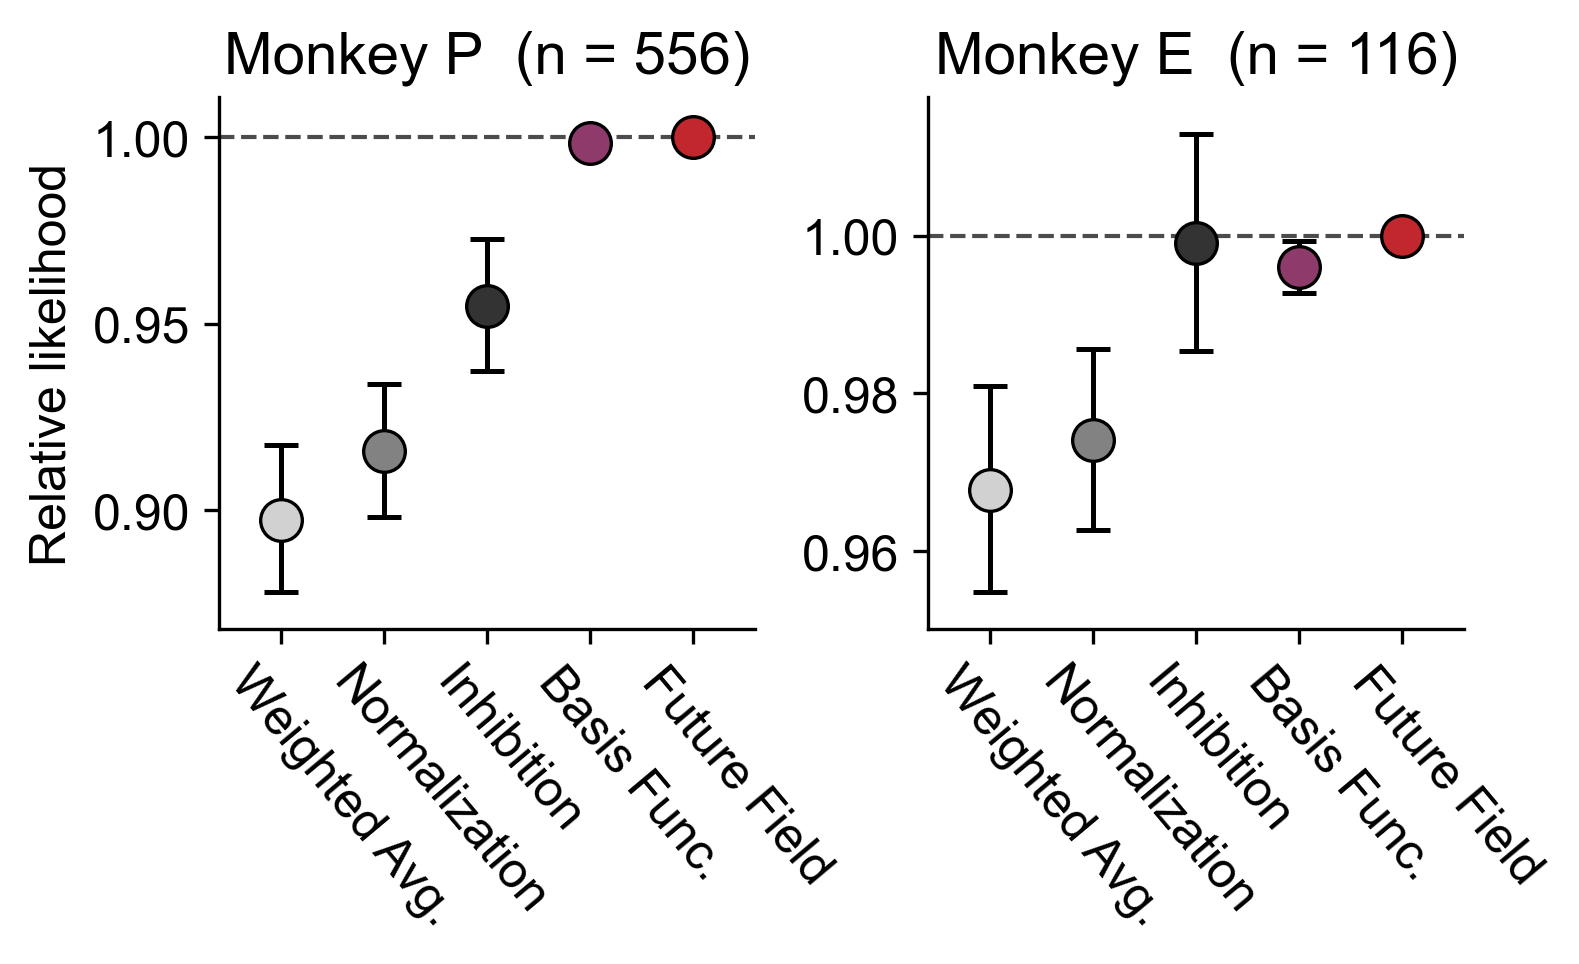

In [3]:
summaries = dict(fits)
for group, per_subject in tables.items():
    pop = summaries[group].drop_duplicates(['subject', 'session', 'unit'])
    n_by_subject = {TITLES[s_]: int((pop['subject'] == s_).sum()) for s_ in SUBJECTS}
    fig = el.plot_elpd(per_subject, COLORS, figsize=FIGSIZE, labels=LABELS, which=ERR_WHICH,
                       xtick_rotation=XTICK_ROTATION, xtick_ha=XTICK_HA,
                       shift_in=XTICK_SHIFT_IN, n_by_subject=n_by_subject,
                       wspace=WSPACE, column_shift_in=COLUMN_SHIFT_IN, ylabel=YLABEL,
                       point_size=POINT_SIZE, err_linewidth=ERR_LINEWIDTH,
                       err_capsize=ERR_CAPSIZE)
    common.save(fig, OUTPUT.format(group=group))
    plt.show()


## The constant-rate model

Every likelihood here is already measured against a neuron that **ignores the stimulus**, so
that model is the origin of the whole scale. It is printed rather than drawn, as in the main
figure: on this axis it sits far below every model shown, and a line there would flatten them
all against the top.

What it gives is the size of the thing being argued over. The models differ from each other by a
few per cent per trial; they differ from a constant rate by very much more, and the *worst* of
them already recovers most of that distance — which is the reading that has to survive the
conditioning for the supplement to be reassuring.

In [4]:
for group, summary in fits:
    for s_ in SUBJECTS:
        t = tables[group][TITLES[s_]]
        _, units, c0 = el.per_neuron_delta(summary, MODELS, t.attrs['reference'], subject=s_)
        worst = t['delta_per_unit'].min()
        print(f'{group}  {TITLES[s_]}  (reference {t.attrs["reference"]})')
        print(f'    constant rate: {c0:+.4f} nats/trial  ->  relative likelihood '
              f'{np.exp(c0):.4f} per trial, {np.exp(c0 * units["n_2obj"].mean()):.3g} per neuron')
        print(f'    worst model:   {worst:+.4f} nats/trial  ->  {np.exp(worst):.4f} per trial, '
              f'i.e. {100 * (1 - worst / c0):.0f}% of the way from a constant rate to the best')


good  Monkey P  (reference future_field)
    constant rate: -0.3815 nats/trial  ->  relative likelihood 0.6828 per trial, 6.75e-137 per neuron
    worst model:   -0.1082 nats/trial  ->  0.8975 per trial, i.e. 72% of the way from a constant rate to the best
good  Monkey E  (reference future_field)
    constant rate: -0.1380 nats/trial  ->  relative likelihood 0.8711 per trial, 6.35e-50 per neuron
    worst model:   -0.0327 nats/trial  ->  0.9678 per trial, i.e. 76% of the way from a constant rate to the best
